# Online Retail II Customer Segmentation — Clustering

**Dataset:** Online Retail II  
**Problem Type:** Unsupervised Learning — Clustering  
**Algorithms:** K-Means Clustering and Agglomerative Hierarchical Clustering

## Objective

The objective of this project is to identify groups of customers with similar purchasing behaviour using clustering algorithms. The Online Retail II dataset contains transactional information from an online retail business, which can be explored to understand customer purchasing patterns.

The project involves dataset exploration, preprocessing, feature engineering, clustering, evaluation using clustering metrics, and visualization of the resulting clusters.

### Note on Unsupervised Learning

The Online Retail II dataset is used for unsupervised customer segmentation. It does not contain a designated target variable for predicting a class or numerical outcome. Therefore, target-distribution plots and feature-target scatterplots are not applicable to the original dataset. Instead, EDA focuses on feature distributions, relationships between numerical variables, transaction trends, and categorical patterns relevant to customer purchasing behaviour.

### Section A

## A1. Dataset Loading and Audit

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
%pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
excel_data = pd.read_excel("E:/SEM-5/ML/ML-PROJECT/ML-Capstone-Project-2026/data/online_retail_II.xlsx",sheet_name=None)
df= pd.concat(excel_data.values(), ignore_index=True)

In [13]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom



## Dataset Shape and Types

In [14]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (1067371, 8)

Column Names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Data Types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 65.1+ MB


## Missing Value Summary

This section checks the number of missing values in each column. Identifying missing values is important because they may require appropriate treatment during preprocessing.

In [16]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

### Observation – Missing Values

- The `Description` column contains 4,382 missing values.
- The `Customer ID` column contains 243,007 missing values.
- All other columns have no missing values.
- Missing customer IDs may limit customer-level analysis because the corresponding transactions cannot be directly associated with a known customer.
- Missing product descriptions may affect product-level interpretation.
- These missing values must be examined and handled during preprocessing before clustering.

In [17]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Value Percentage:")
print(missing_percentage.round(2))

Missing Value Percentage:
Invoice         0.00
StockCode       0.00
Description     0.41
Quantity        0.00
InvoiceDate     0.00
Price           0.00
Customer ID    22.77
Country         0.00
dtype: float64


In [18]:
df = df.dropna(subset=["Customer ID"]).copy()
df["Description"] = df["Description"].fillna("Unknown")
print("Dataset Shape after Handling Missing Values:", df.shape)
print("\nRemaining Missing Values:")
print(df.isnull().sum())

Dataset Shape after Handling Missing Values: (824364, 8)

Remaining Missing Values:
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64


## Duplicate Value Summary

This section checks for duplicate records in the dataset. Duplicate transactions may affect customer-level purchasing patterns and should be examined before clustering.

In [19]:
df.duplicated().sum()

np.int64(26479)

In [20]:
print("Duplicate Records Before Removal:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Dataset Shape after Removing Duplicates:", df.shape)
print("Duplicate Records After Removal:", df.duplicated().sum())

Duplicate Records Before Removal: 26479
Dataset Shape after Removing Duplicates: (797885, 8)
Duplicate Records After Removal: 0


## observation – Duplicate Values

The dataset initially contained 26,479 duplicate records. These records were removed using drop_duplicates(), retaining the first occurrence of each unique row. The dataset is checked again to confirm that no exact duplicate records remain.

## Summary Statistics

This section examines the statistical properties of the numerical and categorical columns in the Online Retail II dataset. Summary statistics help us understand the distribution, range, and variability of transaction quantities and prices, along with the characteristics of the other columns.

## A2. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand transaction patterns, identify unusual distributions, and examine relationships between different attributes in the Online Retail II dataset. This analysis helps identify useful patterns for customer segmentation using clustering algorithms.

## Distribution of Features

The distributions of numerical and categorical features are examined to understand transaction quantities, product prices, and customer purchasing patterns. Identifier columns are not treated as meaningful numerical measurements.

In [23]:
numerical_features = ["Quantity", "Price"]
categorical_features = ["Country","Description","StockCode"]

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['Quantity', 'Price']
Categorical Features: ['Country', 'Description', 'StockCode']


## Numerical Feature Distributions

Histograms are used to examine the distributions of `Quantity` and `Price`. These plots help reveal skewness, concentration of values, and potentially unusual transaction values.

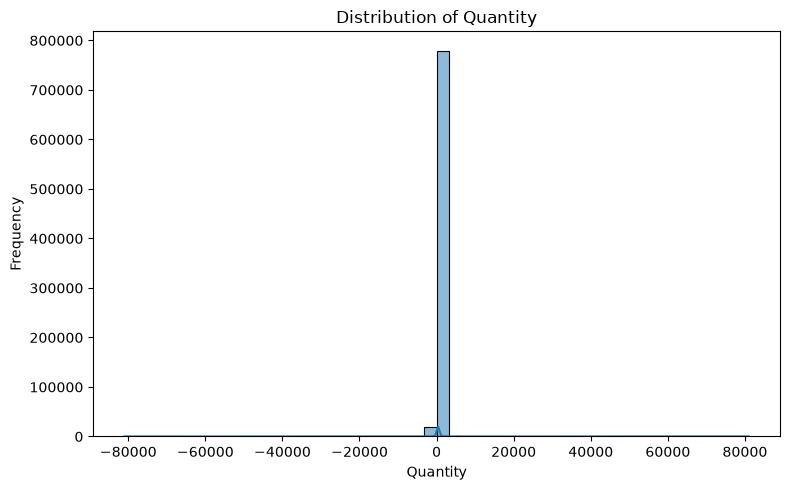

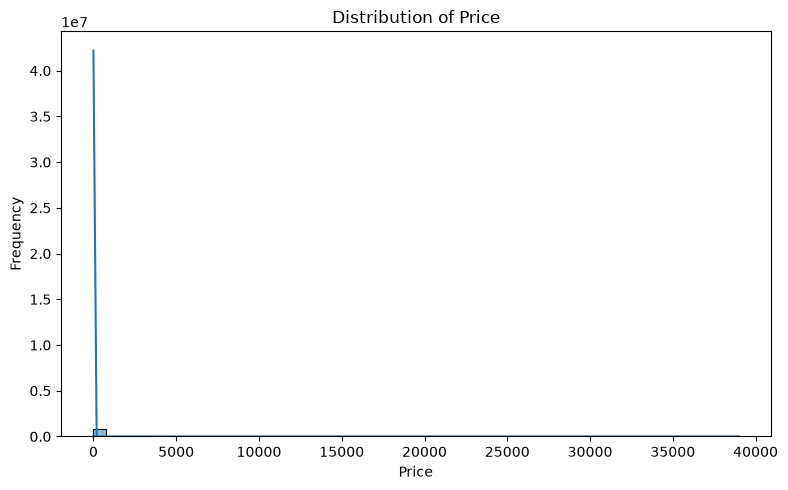

In [24]:
for feature in numerical_features:
    plt.figure(figsize=(8, 5))
    sns.histplot(data=df, x=feature, bins=50, kde=True)
    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

### Observation – Numerical Feature Distributions

The histograms show how transaction quantities and product prices are distributed. The shape of each distribution, including skewness and extreme values, will be examined to understand the purchasing patterns and identify values that may require further investigation during preprocessing.

## Categorical Feature Distributions

The categorical features are examined to understand the variety of countries, products, and stock codes represented in the transactions. Since product descriptions and stock codes can have many unique values, the most frequent categories are visualized for readability.

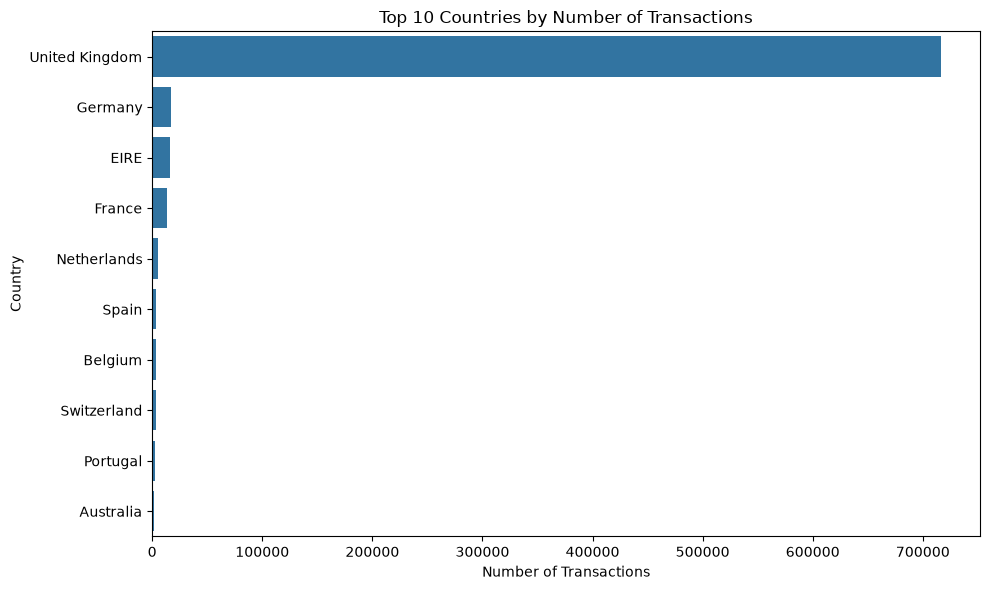

In [25]:
plt.figure(figsize=(10, 6))

country_counts = df["Country"].value_counts().head(10)

sns.barplot(x=country_counts.values, y=country_counts.index)

plt.title("Top 10 Countries by Number of Transactions")
plt.xlabel("Number of Transactions")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

## Distribution of Stock Codes

The stock code identifies the products recorded in transactions. Because the dataset may contain many distinct stock codes, the ten most frequent codes are visualized instead of plotting every category in a single chart.

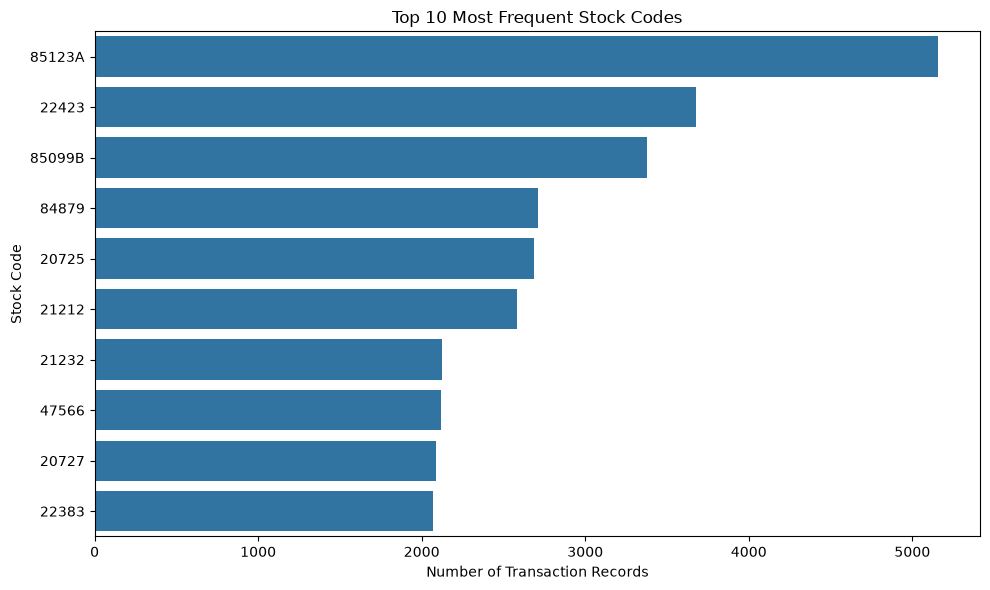

In [29]:
plt.figure(figsize=(10, 6))

stock_counts = df["StockCode"].astype(str).value_counts().head(10)

sns.barplot(x=stock_counts.values, y=stock_counts.index)

plt.title("Top 10 Most Frequent Stock Codes")
plt.xlabel("Number of Transaction Records")
plt.ylabel("Stock Code")
plt.tight_layout()
plt.show()

### Observation – Stock Code Distribution

The bar chart identifies the stock codes appearing most frequently in the transaction records. These frequencies describe how often products occur in the dataset; they do not necessarily represent the highest revenue or the number of distinct customers purchasing each product.

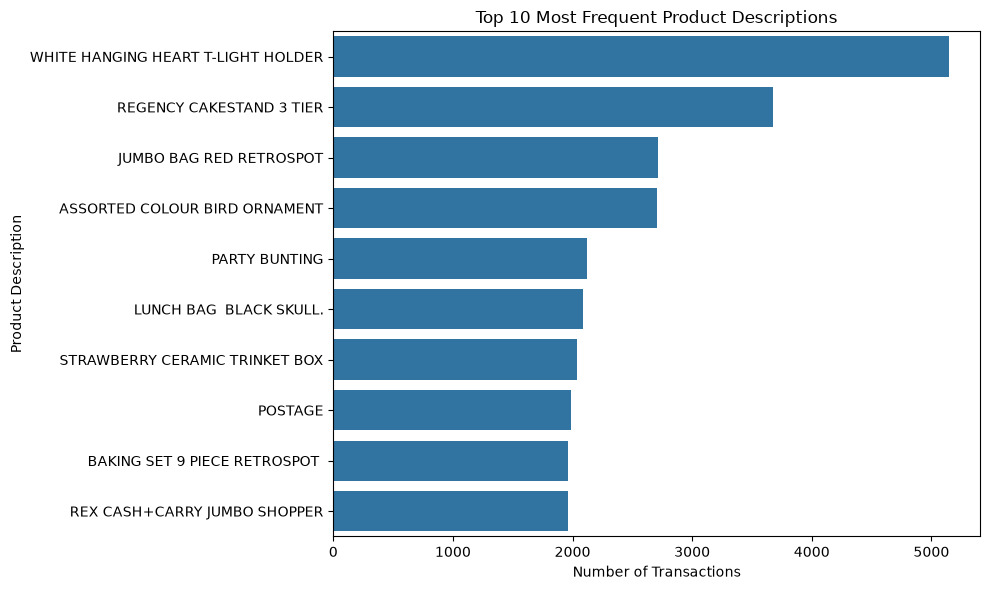

In [26]:
plt.figure(figsize=(10, 6))

description_counts = df["Description"].value_counts().head(10)

sns.barplot(x=description_counts.values, y=description_counts.index)

plt.title("Top 10 Most Frequent Product Descriptions")
plt.xlabel("Number of Transactions")
plt.ylabel("Product Description")
plt.tight_layout()
plt.show()

### Observation – Categorical Feature Distributions

The country distribution highlights the countries contributing the most transactions to the dataset. The product description distribution identifies the most frequently recorded products. These patterns provide an initial understanding of the dataset's transaction composition.

## Transaction Trends Over Time

The invoice date is examined to understand how transaction activity changes over time. Monthly transaction counts can reveal variations in retail activity and provide additional context for understanding customer purchasing behaviour.

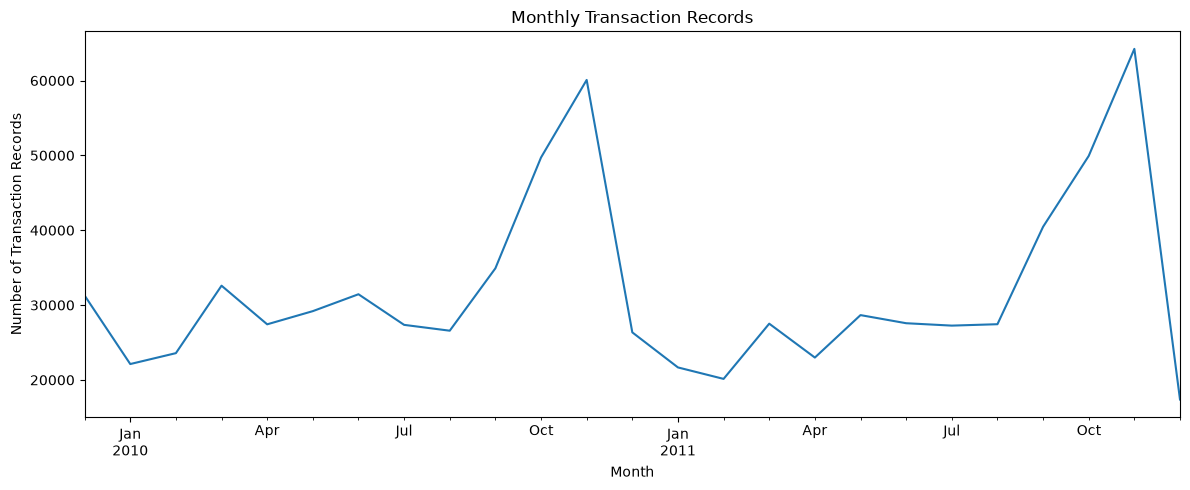

In [27]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

monthly_transactions = (
    df.set_index("InvoiceDate")
      .resample("ME")
      .size()
)

plt.figure(figsize=(12, 5))
monthly_transactions.plot()

plt.title("Monthly Transaction Records")
plt.xlabel("Month")
plt.ylabel("Number of Transaction Records")
plt.tight_layout()
plt.show()

### Observation – Transaction Trends Over Time

The monthly transaction plot illustrates how transaction activity varies across the observed period. Any increases, decreases, or recurring patterns should be described based on the plotted results. These temporal patterns may provide useful context for subsequent customer segmentation.

## Relationships Between Numerical Features

Scatterplots are used to investigate relationships between transaction quantity, unit price, and invoice date. As the dataset does not contain a designated target variable, these plots examine feature-to-feature relationships rather than feature-target relationships. A sample is used where necessary to improve readability.

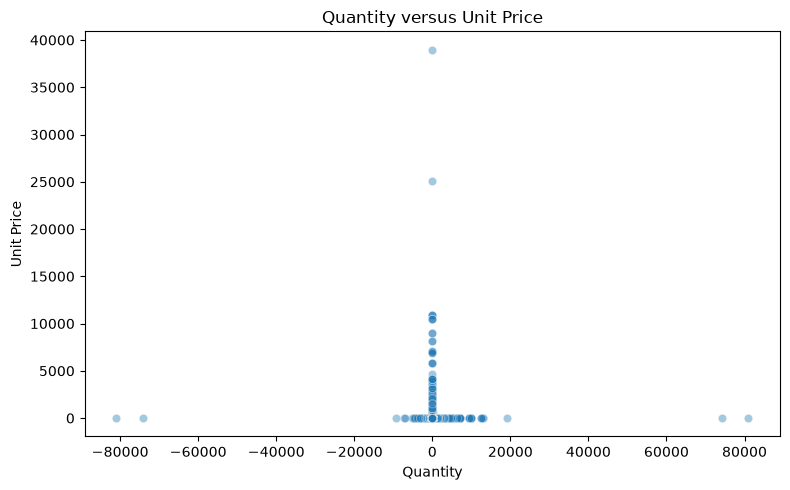

In [31]:

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Quantity",
    y="Price",
    alpha=0.4
)

plt.title("Quantity versus Unit Price")
plt.xlabel("Quantity")
plt.ylabel("Unit Price")
plt.tight_layout()
plt.show()

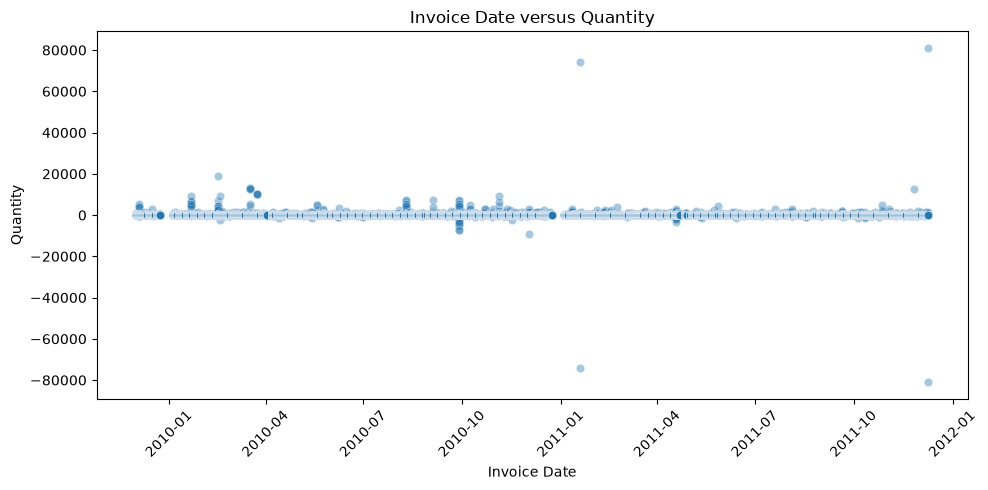

In [33]:
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df,
    x="InvoiceDate",
    y="Quantity",
    alpha=0.4
)

plt.title("Invoice Date versus Quantity")
plt.xlabel("Invoice Date")
plt.ylabel("Quantity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Correlation Heatmap

A correlation heatmap is used to examine the relationships between numerical features in the dataset. It helps identify whether numerical variables are positively or negatively associated and provides an overview of their relationships before clustering.

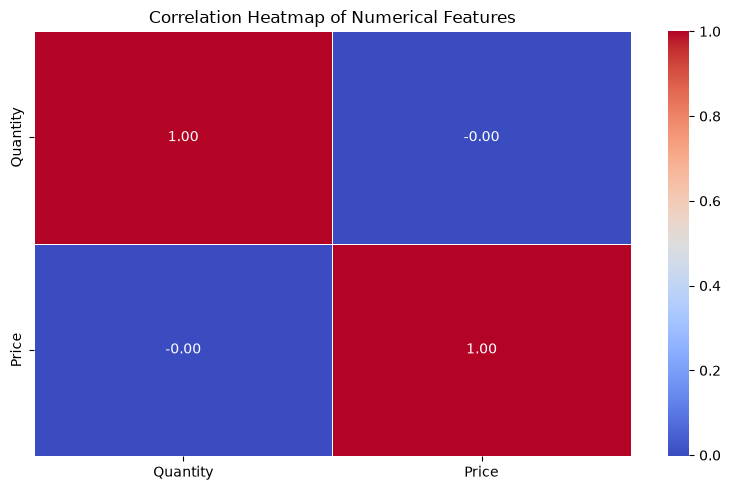

In [28]:
correlation_matrix = df[numerical_features].corr()

plt.figure(figsize=(8, 5))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

### Observation – Correlation Heatmap

The heatmap displays the correlation between `Quantity` and `Price`. The diagonal values represent the perfect correlation of each feature with itself. The off-diagonal value indicates the strength and direction of the linear relationship between quantity and price. The observed relationship should be interpreted based on the heatmap output.

## A3. EDA Insights

The exploratory data analysis provides an overview of the Online Retail II transaction dataset and its suitability for customer segmentation.

- **Data quality:** The initial audit identified missing product descriptions, missing customer identifiers, and duplicate records. These were examined and handled during dataset preparation.
- **Numerical distributions:** Histograms and boxplots show the spread of transaction quantities and unit prices and help identify values that may require further investigation.
- **Categorical distributions:** The country, product-description, and stock-code plots summarize the most frequent categories in the transaction records.
- **Temporal coverage:** The invoice date summary establishes the period covered by the dataset.
- **Transaction trends:** The monthly transaction plot shows how the number of transaction records varies over time.
- **Correlation analysis:** The heatmap summarizes the linear relationship between quantity and unit price.
- **Feature relationships:** Scatterplots explore relationships between quantity and price, and between invoice date and quantity.

The Online Retail II dataset is suitable for further customer-level analysis because it records purchasing activity across invoices and products. However, customer segmentation requires customer-level features to be constructed and appropriately scaled during preprocessing. These steps are handled in the subsequent preprocessing and feature-engineering stage.

## section B

In [34]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["Invoice"] = df["Invoice"].astype(str)

print("Original transaction rows:", len(df))
print("Unique customers:", df["Customer ID"].nunique())

Original transaction rows: 797885
Unique customers: 5942


In [35]:
df = df.dropna(subset=["Customer ID", "InvoiceDate"]).copy()

df = df[
    (~df["Invoice"].str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
].copy()

df["Sales"] = df["Quantity"] * df["Price"]

print("Valid sales transaction rows:", len(df))
print("Customers remaining:", df["Customer ID"].nunique())

Valid sales transaction rows: 779425
Customers remaining: 5878


In [36]:
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

df = df.groupby("Customer ID").agg(
    LastPurchaseDate=("InvoiceDate", "max"),
    Frequency=("Invoice", "nunique"),
    Monetary=("Sales", "sum"),
    TotalQuantity=("Quantity", "sum"),
    AveragePrice=("Price", "mean")
).reset_index()

df["Recency"] = (
    reference_date - df["LastPurchaseDate"]
).dt.days

df = df.drop(columns=["Customer ID", "LastPurchaseDate"])

print("Customer-level dataset shape:", df.shape)
display(df.head())

Customer-level dataset shape: (5878, 5)


,Frequency,Monetary,TotalQuantity,AveragePrice,Recency
0,12,77556.46,74285,6.100000,326
1,8,4921.53,2967,2.498063,2
2,5,2019.40,2714,3.786275,75
3,4,4428.69,1624,8.459657,19
4,1,334.40,197,3.841176,310


In [37]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nFeature summary:")
display(df.describe())

Missing values:
Frequency        0
Monetary         0
TotalQuantity    0
AveragePrice     0
Recency          0
dtype: int64

Duplicate rows: 1

Feature summary:


,Frequency,Monetary,TotalQuantity,AveragePrice,Recency
count,5878.000000,5878.000000,5878.000000,5878.000000,5878.000000
mean,6.289384,2955.904095,1788.695475,8.580948,201.331916
std,13.009406,14440.852688,8876.297196,176.315876,209.338707
min,1.000000,2.950000,1.000000,0.151333,1.000000
25%,1.000000,342.280000,187.000000,2.296310,26.000000
50%,3.000000,867.740000,480.000000,2.964136,96.000000
75%,7.000000,2248.305000,1350.000000,3.845556,380.000000
max,398.000000,580987.040000,367193.000000,10953.500000,739.000000


In [38]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

X = df.copy()

print("Features used for clustering:", X.columns.tolist())

X_train, X_test = train_test_split(
    X,
    test_size=0.20,
    random_state=42
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Features used for clustering: ['Frequency', 'Monetary', 'TotalQuantity', 'AveragePrice', 'Recency']
Training shape: (4702, 5)
Testing shape: (1176, 5)


In [39]:
X_train_log = np.log1p(X_train)
X_test_log = np.log1p(X_test)

scaler = RobustScaler()

X_train_scaled = scaler.fit_transform(X_train_log)
X_test_scaled = scaler.transform(X_test_log)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (4702, 5)
Scaled testing shape: (1176, 5)


In [40]:
print("Training data contains NaN:", np.isnan(X_train_scaled).any())
print("Training data contains infinity:", np.isinf(X_train_scaled).any())

print("Testing data contains NaN:", np.isnan(X_test_scaled).any())
print("Testing data contains infinity:", np.isinf(X_test_scaled).any())

Training data contains NaN: False
Training data contains infinity: False
Testing data contains NaN: False
Testing data contains infinity: False


## SECTION - B (REVIEW - 2)

### K-Means Clustering Algorithm

K-Means is an unsupervised machine learning algorithm that groups similar customers into clusters based on their feature values. It works iteratively by assigning data points to the nearest centroid and updating the centroids until the algorithm converges.

The algorithm follows these steps:

1. **Choose the number of clusters (\(K\)):** Specify the number of customer groups to create. In this initial implementation, we use \(K=3\) provisionally; the Elbow Method will help us evaluate this choice later.

2. **Initialize centroids:** Select initial cluster centers using the K-Means initialization strategy. Here, `n_init=10` instructs scikit-learn to run the algorithm with 10 initializations and retain the best result.

3. **Assign customers to the nearest centroid:** Calculate the Euclidean distance between each customer and the cluster centroids, assigning each customer to the nearest centroid.

4. **Update centroids:** Recalculate each centroid as the mean of the feature vectors assigned to that cluster.

5. **Repeat until convergence:** Continue assigning customers and updating centroids until the algorithm converges or reaches its iteration limit.

For this project, K-Means is applied to the previously scaled training data containing the five engineered customer features: Frequency, Monetary, TotalQuantity, AveragePrice, and Recency. We use `random_state=42` to make the results reproducible.

In [48]:
from sklearn.cluster import KMeans
kmeans_model = KMeans(n_clusters=3,init="k-means++",n_init=10,random_state=42)
kmeans_labels = kmeans_model.fit_predict(X_train_scaled)

train_clustered = X_train.copy()
train_clustered["KMeans_Cluster"] = kmeans_labels

print("K-Means implementation completed successfully.")
print("Number of clusters:", len(set(kmeans_labels)))
print("Cluster labels:", sorted(set(kmeans_labels)))
print("Number of training customers:", len(kmeans_labels))
display(train_clustered["KMeans_Cluster"].value_counts().sort_index().rename("Number of Customers").to_frame())

K-Means implementation completed successfully.
Number of clusters: 3
Cluster labels: [np.int32(0), np.int32(1), np.int32(2)]
Number of training customers: 4702


,Number of Customers
KMeans_Cluster,
0,2646
1,2014
2,42


### Observation

The K-Means algorithm was successfully implemented with \(K = 3\), producing three distinct cluster labels: 0, 1, and 2. The 4,702 training customers were distributed across these clusters as follows:

- **Cluster 0:** 2,646 customers
- **Cluster 1:** 2,014 customers
- **Cluster 2:** 42 customers

Cluster 0 contains the largest number of customers, followed by Cluster 1. Cluster 2 is considerably smaller, containing only 42 customers. This indicates that the algorithm has formed clusters of unequal sizes. Further evaluation using clustering metrics and cluster visualizations is required to assess the quality and separation of these groups.

## B2 Evaluation metrics

### Determining the Optimal Number of Clusters Using the Elbow Method

The Elbow Method helps identify a suitable number of clusters (\(K\)) for the K-Means algorithm. It evaluates how the within-cluster sum of squares (WCSS), also called *inertia*, changes as the number of clusters increases.

For each value of \(K\), K-Means assigns customers to clusters and calculates the sum of squared distances between each customer and its assigned cluster centroid.

As \(K\) increases, inertia generally decreases because customers can be assigned to more closely positioned centroids. However, increasing the number of clusters also increases model complexity.

The inertia values are plotted against different values of \(K\). The point where the rate of decrease begins to slow noticeably is called the *elbow*. This point can suggest a suitable number of clusters.

In this experiment, the Elbow Method is applied to the scaled training data, `X_train_scaled`, using a fixed random state to ensure reproducibility.

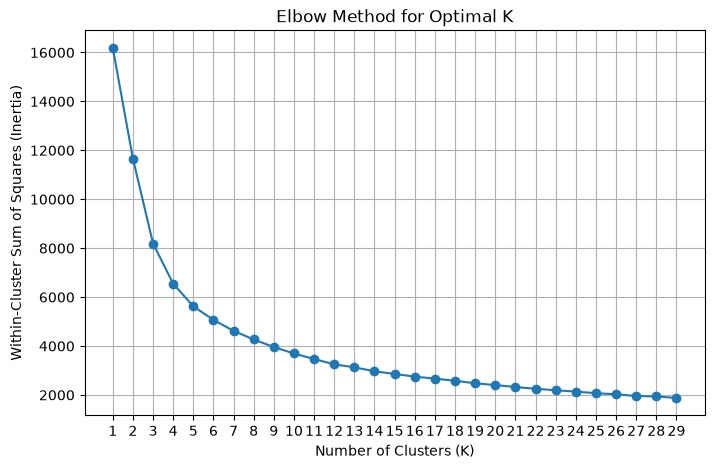

In [46]:
import matplotlib.pyplot as plt

inertia_values = []
k_values = range(1, 30)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    model.fit(X_train_scaled)
    inertia_values.append(model.inertia_)


plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (Inertia)")
plt.title("Elbow Method for Optimal K")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

### Observation

The Elbow Method was applied for different values of \(K\) to determine a suitable number of clusters. The inertia decreases substantially as \(K\) increases from 1 to approximately 4. Beyond this point, the reduction in inertia becomes more gradual.

The curve suggests that the elbow lies approximately in the range of \(K=4\) to \(K=6\). This indicates diminishing returns from adding more clusters. The final value of \(K\) should also be assessed using clustering evaluation metrics and cluster visualizations.

### Comparing K-Means Clustering Configurations

The Elbow Method provides a visual estimate of the optimal number of clusters, but it does not independently establish clustering quality. Therefore, multiple values of \(K\) are evaluated using three internal clustering metrics.

- **Silhouette Score:** Measures how well each customer fits within its assigned cluster compared with other clusters. Higher values generally indicate better-defined clusters.
- **Davies–Bouldin Index:** Measures the similarity between clusters based on their compactness and separation. Lower values generally indicate better clustering.
- **Calinski–Harabasz Index:** Compares between-cluster dispersion with within-cluster dispersion. Higher values generally indicate better-separated clusters.

All configurations are fitted using the same scaled training data. Comparing the metrics across \(K=3,4,5,6\) helps identify a suitable configuration without relying solely on the Elbow curve.

In [50]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

evaluation_results = []

for k in [3, 4, 5, 6]:
    model = KMeans(n_clusters=k,init="k-means++",n_init=10,random_state=42)
    labels = model.fit_predict(X_train_scaled)

    evaluation_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette Score": silhouette_score(
            X_train_scaled, labels
        ),
        "Davies-Bouldin Index": davies_bouldin_score(
            X_train_scaled, labels
        ),
        "Calinski-Harabasz Index": calinski_harabasz_score(
            X_train_scaled, labels
        )
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(
    evaluation_df.round(4)
)

,K,Inertia,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,3,8190.8066,0.3290,0.9407,2292.6794
1,4,6546.9861,0.2910,1.0098,2304.9976
2,5,5624.3866,0.2532,1.0484,2204.5150
3,6,5067.3293,0.2516,1.0557,2060.3114


### Observation

The K-Means configurations with \(K=3,4,5,\) and \(6\) were evaluated using inertia, Silhouette Score, Davies–Bouldin Index, and Calinski–Harabasz Index.

The Silhouette Score is highest at \(K=3\) (0.3290), while the Davies–Bouldin Index is lowest at \(K=3\) (0.9407). The Calinski–Harabasz Index reaches its highest value at \(K=4\) (2304.9976). Inertia decreases as the number of clusters increases.

Considering the results collectively, \(K=3\) is a reasonable choice because it performs best on two of the three clustering quality metrics. However, the final selection should also consider the cluster distributions and visualizations.

## K Means Model

In [51]:
from sklearn.cluster import KMeans

kmeans_model = KMeans(n_clusters=3,init="k-means++",n_init=10,random_state=42)
kmeans_labels = kmeans_model.fit_predict(X_train_scaled)

train_clustered = X_train.copy()
train_clustered["KMeans_Cluster"] = kmeans_labels

print("Final K-Means model fitted successfully.")
print("\nCluster distribution:")
display(
    train_clustered["KMeans_Cluster"]
    .value_counts()
    .sort_index()
    .rename("Number of Customers")
    .to_frame()
)

Final K-Means model fitted successfully.

Cluster distribution:


,Number of Customers
KMeans_Cluster,
0,2646
1,2014
2,42


### K-Means Cluster Visualization Using PCA

### Visualizing K-Means Clusters Using Principal Component Analysis (PCA)

The customer dataset contains five numerical features, making it difficult to visualize the clusters directly. Principal Component Analysis (PCA) reduces the feature space to two principal components while retaining as much of the data's variance as possible.

PCA is applied to the scaled training features to obtain a two-dimensional representation of the customers. The cluster labels generated by the final K-Means model are then used to assign colours to the points in the scatter plot.

Each point represents a customer, and its colour indicates the cluster assigned by K-Means. This visualization helps examine the distribution and overlap of clusters in the reduced feature space.

PCA is used only for visualization here; the K-Means model was fitted using all five scaled features.

Variance explained by PC1: 51.8 %
Variance explained by PC2: 39.16 %
Total variance explained: 90.95 %


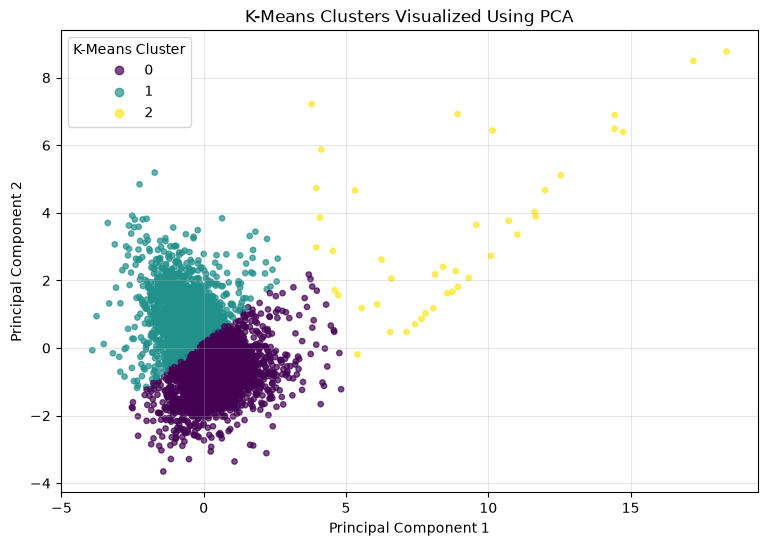

In [52]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
explained_variance = pca.explained_variance_ratio_

print("Variance explained by PC1:",round(explained_variance[0] * 100, 2), "%")
print("Variance explained by PC2:",round(explained_variance[1] * 100, 2), "%")
print("Total variance explained:",round(explained_variance.sum() * 100, 2), "%")

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=15,
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters Visualized Using PCA")
plt.legend(*scatter.legend_elements(),title="K-Means Cluster")
plt.grid(True, alpha=0.3)
plt.show()

### Observation

PCA was applied to the five scaled customer features to visualize the K-Means clustering results in two dimensions. The first principal component explains 51.80% of the variance, while the second explains 39.16%. Together, they explain 90.95% of the total variance.

The scatter plot shows three clusters with different distributions. Clusters 0 and 1 occupy relatively dense regions and exhibit some overlap near their boundaries. Cluster 2 contains comparatively few points that extend farther from the main customer groups, suggesting that it may represent customers with distinct purchasing patterns.

Overall, the PCA visualization provides a useful representation of the clustering structure. However, the apparent separation in two dimensions should be interpreted alongside the clustering evaluation metrics and further visual analysis.

## t-SNE visualization

### Visualizing K-Means Clusters Using t-SNE

t-distributed Stochastic Neighbor Embedding (t-SNE) is a nonlinear dimensionality-reduction technique that maps high-dimensional data into a lower-dimensional space. It attempts to preserve local similarities between data points, making it useful for exploring whether customers assigned to different clusters form visually distinct groups.

In this experiment, t-SNE reduces the five scaled customer features to two dimensions. The resulting scatter plot uses the cluster labels from the final K-Means model to colour the customers.

Unlike PCA, t-SNE focuses on local neighbourhood structure and does not directly show the percentage of total variance explained. Distances between well-separated groups in a t-SNE plot should therefore be interpreted cautiously.

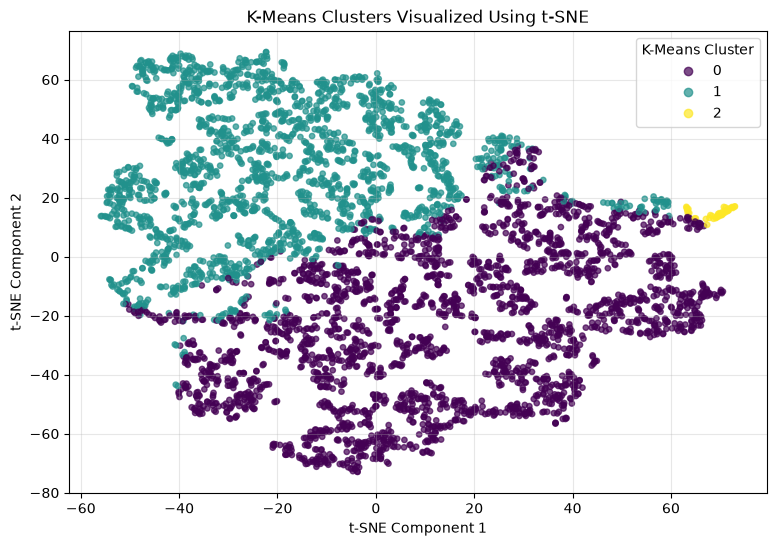

In [53]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

X_train_tsne = tsne.fit_transform(X_train_scaled)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_train_tsne[:, 0],
    X_train_tsne[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=15,
    alpha=0.7
)

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("K-Means Clusters Visualized Using t-SNE")
plt.legend(*scatter.legend_elements(),title="K-Means Cluster")
plt.grid(True, alpha=0.3)
plt.show()

### Observation

The t-SNE technique was applied to the five scaled customer features to visualize the K-Means clustering results in two dimensions. The plot shows that Clusters 0 and 1 occupy different regions, although some overlap is visible near their boundaries. Cluster 2 forms a comparatively small group of points toward the right side of the visualization.

The t-SNE plot provides a complementary view of the cluster structure by emphasizing local similarities between customers. The visible separation suggests that some customer groups have different feature patterns. However, t-SNE is primarily a visualization technique, and the apparent distances between groups should not be treated as a definitive measure of cluster quality.

## Analyze customer characteristics by cluster

In [55]:
cluster_profile = (
    train_clustered
    .groupby("KMeans_Cluster")
    .mean()
    .round(2)
)

print("Average customer characteristics by K-Means cluster:")
display(cluster_profile)

Average customer characteristics by K-Means cluster:


,Frequency,Monetary,TotalQuantity,AveragePrice,Recency
KMeans_Cluster,,,,,
0,2.03,502.16,276.76,3.46,294.81
1,12.00,6043.14,3731.21,3.07,75.13
2,5.40,7279.18,3936.86,704.09,384.10


### Observation

The cluster profiles reveal three groups with different purchasing behaviours.

- **Cluster 0:** Customers have the lowest average purchase frequency (2.03), monetary value (502.16), and total quantity (276.76). Their average recency is 294.81 days, indicating that their most recent purchase was relatively long ago compared with Cluster 1.
- **Cluster 1:** Customers have the highest average purchase frequency (12.00), monetary value (6043.14), and total quantity (3731.21). Their average recency is 75.13 days, indicating more recent purchasing activity. This group represents relatively frequent and high-value customers.
- **Cluster 2:** Customers have a high average monetary value (7279.18) and total quantity (3936.86), but a much higher average recency (384.10 days) than the other groups. This suggests that these customers made substantial purchases historically but have not purchased recently.

Overall, K-Means identifies groups with different purchasing frequency, spending levels, and recency. These profiles help translate the cluster assignments into interpretable customer segments.

## Evaluate the final model

In [56]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

kmeans_metrics = pd.DataFrame({
    "Metric": [
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Calinski-Harabasz Index"
    ],
    "Score": [
        silhouette_score(X_train_scaled, kmeans_labels),
        davies_bouldin_score(X_train_scaled, kmeans_labels),
        calinski_harabasz_score(X_train_scaled, kmeans_labels)
    ]
})

display(kmeans_metrics.round(4))

,Metric,Score
0,Silhouette Score,0.3290
1,Davies-Bouldin Index,0.9407
2,Calinski-Harabasz Index,2292.6794


### Evaluation of the Final K-Means Model

The final K-Means model with \(K=3\) was evaluated using three internal clustering metrics.

- **Silhouette Score: 0.3290** — indicates some cluster structure, although separation between clusters is not strong.
- **Davies–Bouldin Index: 0.9407** — measures cluster similarity; lower values are generally preferred.
- **Calinski–Harabasz Index: 2292.6794** — measures the ratio of between-cluster dispersion to within-cluster dispersion; higher values are generally preferred when comparing configurations evaluated on the same data.

The three metrics, together with the PCA and t-SNE visualizations, provide complementary evidence for evaluating the clustering results. The cluster profiles also reveal differences in customer purchasing behaviour. Overall, the model identifies three customer groups, although the degree of separation and the small size of Cluster 2 should be considered when interpreting the results.